# 01 · Exploratory analysis: housing vacancy in Ciudad Juárez

Uses `data/ageb_features.csv`: INEGI Census 2020 by AGEB (neighborhood) joined with IMIP layers. The spatial joins run in `scripts/prepare_features.py` (needs geopandas), so this notebook only needs pandas, numpy and matplotlib and runs in the LinuxONE Jupyter container.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAW = Path("../data/raw")

def geojson_frame(path):
    """GeoJSON points to a DataFrame with lon/lat, without geopandas."""
    feats = json.loads(Path(path).read_text())["features"]
    rows = [{**f["properties"], "lon": f["geometry"]["coordinates"][0], "lat": f["geometry"]["coordinates"][1]}
            for f in feats if f.get("geometry")]
    return pd.DataFrame(rows)

a = pd.read_csv("../data/ageb_features.csv")
print(len(a), "AGEBs |", int(a.VIVPAR_DES.sum()), "vacant homes")

567 AGEBs | 55213 vacant homes


## What is associated with vacancy?
Spearman rank correlation (robust to outliers, no linearity assumption). Exploratory only, not causal.

In [2]:
cols = ["year_urbanized", "km_center", "km_maquila", "maquilas_3km", "km_brt", "km_health",
        "crimes2020_per1000", "crimes2025_per1000", "property_value", "GRAPROES"]
a[cols + ["pct_vacant"]].corr("spearman")["pct_vacant"].drop("pct_vacant").sort_values().round(2)

year_urbanized       -0.41
maquilas_3km         -0.32
km_center            -0.30
property_value       -0.19
GRAPROES             -0.16
km_health            -0.08
km_brt                0.02
km_maquila            0.11
crimes2025_per1000    0.17
crimes2020_per1000    0.22
Name: pct_vacant, dtype: float64

In [3]:
a["decade"] = a.year_urbanized // 10 * 10
a.groupby("decade").agg(agebs=("CVEGEO", "size"), median_pct_vacant=("pct_vacant", "median"),
                        vacant_homes=("VIVPAR_DES", "sum")).round(1)

,agebs,median_pct_vacant,vacant_homes
decade,,,
1890.0,1,24.8,99.0
1910.0,4,30.1,449.0
1930.0,9,27.4,1457.0
1950.0,22,20.4,2431.0
1960.0,70,16.5,6597.0
1970.0,77,10.3,5392.0
1980.0,52,9.0,4121.0
1990.0,150,9.0,12045.0
2000.0,109,8.2,13765.0


In [4]:
# Top AGEBs by number of vacant homes: distant 2006-2008 developments dominate
a.nlargest(10, "VIVPAR_DES")[["CVEGEO", "year_urbanized", "pct_vacant", "VIVPAR_DES", "km_center", "maquilas_3km"]].round(1)

,CVEGEO,year_urbanized,pct_vacant,VIVPAR_DES,km_center,maquilas_3km
89,0803700018248,NaN,91.7,1076.0,22.6,1
500,0803700018021,NaN,36.4,967.0,24.7,17
1,0803700018106,2008.0,74.7,737.0,26.0,1
536,0803700018017,NaN,8.7,711.0,22.7,28
390,0803700017822,2008.0,20.1,514.0,21.0,43
540,080370001756A,1997.0,26.8,491.0,11.4,49
315,0803700016913,2006.0,19.9,472.0,15.1,104
343,0803700017894,2008.0,26.7,448.0,23.7,1
383,0803700017108,2020.0,14.9,398.0,14.2,51
85,0803700017926,2007.0,20.1,363.0,22.8,10


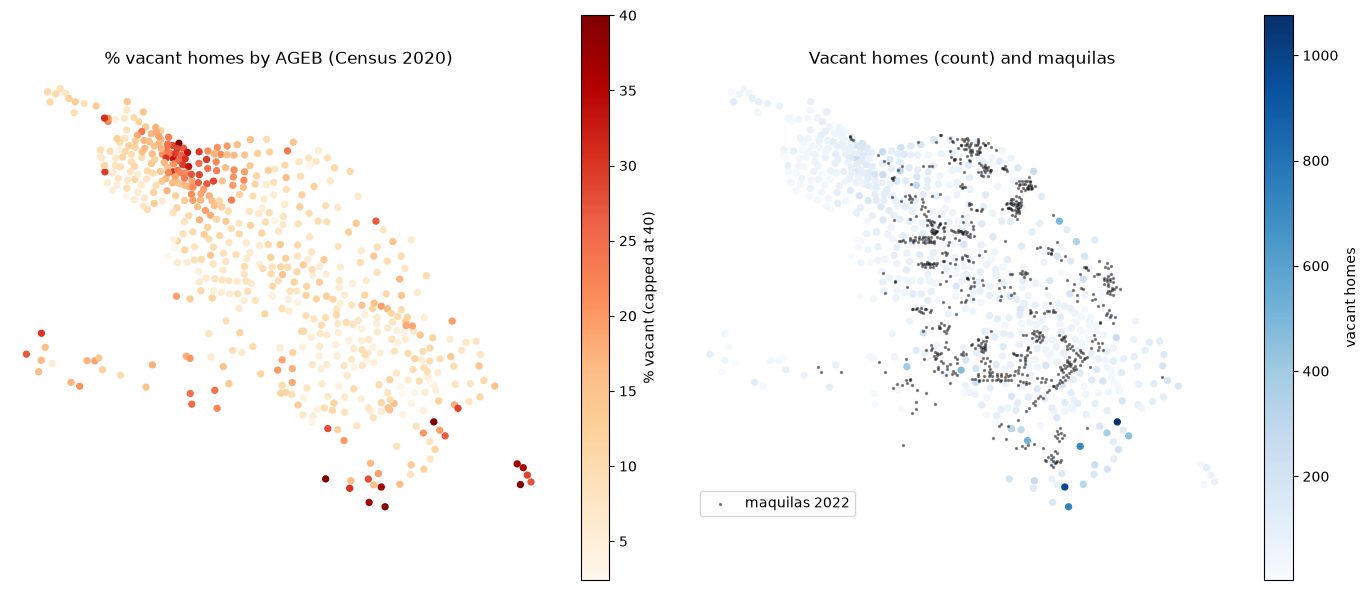

In [5]:
maq = geojson_frame(RAW / "imip" / "maquilas_2022.geojson")
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
s = ax[0].scatter(a.lon, a.lat, c=a.pct_vacant.clip(upper=40), cmap="OrRd", s=18)
fig.colorbar(s, ax=ax[0], label="% vacant (capped at 40)")
ax[0].set_title("% vacant homes by AGEB (Census 2020)")
s = ax[1].scatter(a.lon, a.lat, c=a.VIVPAR_DES, cmap="Blues", s=18)
ax[1].scatter(maq.lon, maq.lat, s=2, color="black", alpha=.4, label="maquilas 2022")
fig.colorbar(s, ax=ax[1], label="vacant homes")
ax[1].set_title("Vacant homes (count) and maquilas")
ax[1].legend(loc="lower left")
pad = 0.01
for x in ax:
    x.set_xlim(a.lon.min() - pad, a.lon.max() + pad)
    x.set_ylim(a.lat.min() - pad, a.lat.max() + pad)
    x.set_aspect("equal")
    x.set_axis_off()
plt.tight_layout()

## Crime data as a monthly stream
IMIP publishes geolocated crime reports with month, hour and type; 2026 is updated through September.

In [6]:
d26 = geojson_frame(RAW / "imip" / "delitos_2026.geojson")
print(d26.MES_NUMERO.value_counts().sort_index().to_dict())
d26.ID_GRUPO.value_counts().head(10)

{1: 715, 2: 715, 3: 731, 4: 802, 5: 730, 6: 713, 7: 809, 8: 746, 9: 747, 10: 1, 11: 1, 12: 1}


ID_GRUPO
DET. ORDEN PENDIENTE                   1520
VIOLENCIA FAMILIAR                      873
ROBO A CASA COMERCIAL CON VIOLENCIA     541
ROBO DE VEHICULO S/V                    409
DAÑOS                                   388
ROBO A CASA COMERCIAL SIN VIOLENCIA     347
ARMAS DECOMISADAS                       237
LESIONES OTROS                          184
HOMICIDIO C ARMA DE FUEGO               179
ROBO SIN VIOLENCIA                      167
Name: count, dtype: int64